# C9 analysis with Alpha Genome

## Imports

In [ ]:
from alphagenome import colab_utils
from alphagenome.data import gene_annotation
from alphagenome.data import genome
from alphagenome.data import transcript as transcript_utils
from alphagenome.interpretation import ism
from alphagenome.models import dna_client
from alphagenome.models import variant_scorers
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import pandas as pd
import os
import numpy as np
import pyranges as pr
import pysam
from collections import defaultdict

api_key = os.environ.get('ALPHAGENOME_API_KEY')
dna_model = dna_client.create(api_key)

## Load C9orf72 Gene Annotation from GTF

In [2]:
# Quick C9orf72 interval definition
c9orf72_interval = genome.Interval(
    chromosome="chr9",
    start=27546546,
    end=27573866,
    strand="-",
)

# FAST: fetch only the region from tabix-indexed GTF
GTF_GZ = "/net/intdev/devdcode/gaetano/data/gencode/gencode.v49.annotation.sorted.gtf.gz"
tbx = pysam.TabixFile(GTF_GZ)

def parse_gtf_attrs(attr_str: str) -> dict:
    """Parse GTF attributes: key "value"; key2 "value2";"""
    out = {}
    for part in attr_str.strip().split(";"):
        part = part.strip()
        if not part:
            continue
        k, v = part.split(" ", 1)
        out[k] = v.strip().strip('"')
    return out

# Collect transcript metadata and exons for the gene
tx_meta = {}
tx_exons = defaultdict(list)

for line in tbx.fetch(c9orf72_interval.chromosome, c9orf72_interval.start, c9orf72_interval.end):
    chrom, source, feature, start, end, score, strand, frame, attrs = line.split("\t")
    if strand != c9orf72_interval.strand:
        continue

    a = parse_gtf_attrs(attrs)

    # Restrict to the gene of interest
    if a.get("gene_name") != "C9orf72":
        continue

    start_i = int(start)
    end_i = int(end)

    if feature == "transcript":
        tx_id = a.get("transcript_id")
        if tx_id:
            tx_meta[tx_id] = {
                "transcript_id": tx_id,
                "gene_name": a.get("gene_name"),
                "gene_id": a.get("gene_id"),
                "transcript_type": a.get("transcript_type"),
                "transcript_name": a.get("transcript_name"),
                "tag": a.get("tag"),
                "chromosome": chrom,
                "start": start_i,
                "end": end_i,
                "strand": strand,
            }

    elif feature == "exon":
        tx_id = a.get("transcript_id")
        exon_number = a.get("exon_number")
        if tx_id:
            tx_exons[tx_id].append((start_i, end_i, exon_number))

# Build a simple transcript list (sorted exons)
transcripts = []
for tx_id, meta in tx_meta.items():
    exons = sorted(tx_exons.get(tx_id, []), key=lambda x: x[0])
    transcripts.append({
        **meta,
        "exons": [{"start": s, "end": e, "exon_number": n} for s, e, n in exons],
    })

# Sort transcripts by genomic start
transcripts.sort(key=lambda t: t["start"])

print(f"Loaded {len(transcripts)} transcript(s) for C9orf72 from tabix-indexed GTF.")


Loaded 23 transcript(s) for C9orf72 from tabix-indexed GTF.


## Define Variant at Repeat Expansion Site

In [3]:
# C9orf72 locus: chr9:27,546,546-27,573,866 (GRCh38)
# Repeat expansion: chr9:27,573,483-27,573,546
REPEAT_START = 27573483
REPEAT_END = 27573546

variant = genome.Variant(
    chromosome='chr9', 
    position=REPEAT_END,  # Within the repeat expansion region
    reference_bases='G', 
    alternate_bases='GGGGCC'*1000
)

print(f"Variant created: {variant.chromosome}:{variant.position}")
print(f"  REF: {variant.reference_bases}")
print(f"  ALT: {variant.alternate_bases[:50]}... ({len(variant.alternate_bases)} bp)")


Variant created: chr9:27573546
  REF: G
  ALT: GGGGCCGGGGCCGGGGCCGGGGCCGGGGCCGGGGCCGGGGCCGGGGCCGG... (6000 bp)


## Run AlphaGenome Prediction

### Ontology

In [4]:
output_metadata = dna_model.output_metadata(
    dna_client.Organism.HOMO_SAPIENS
).concatenate()

In [ ]:
biosample_of_interest = [
    # Core motor system
    "motor neuron",
    "spinal cord",
    "neuron",
    "glutamatergic neuron",
    
    # Glial cells
    "astrocyte",
    "astrocyte of the spinal cord",
    "astrocyte of the hippocampus",
    "oligodendrocyte precursor cell",
    "Schwann cell",
    
    # CNS support / vascular
    "central nervous system pericyte",
    "brain pericyte",
    "brain microvascular endothelial cell",
    
    
    # Brain regions relevant for ALS / ALS-FTD
    "frontal cortex",
    "temporal lobe",
    "dorsolateral prefrontal cortex",
    "anterior cingulate cortex",
    "cerebellum",
    "substantia nigra",
]

# Find matching ontology terms for each biosample
matching_terms = {}
for term in biosample_of_interest:
    matches = output_metadata[output_metadata['biosample_name'] == term]['ontology_curie'].unique()
    if len(matches) > 0:
        matching_terms[term] = matches[0]  # Take first match
        print(f"✓ {term:45} → {matches[0]}")
    else:
        print(f"✗ {term:45} → NOT FOUND")


print(f"\nFound {len(matching_terms)} / {len(biosample_of_interest)} biosamples")
print(f"\nOntology terms for prediction: {list(matching_terms.values())}")


✓ motor neuron                                  → CL:0000100
✓ spinal cord                                   → UBERON:0002240
✓ neuron                                        → CL:0000540
✓ glutamatergic neuron                          → CL:0000679
✓ astrocyte                                     → CL:0000127
✓ astrocyte of the spinal cord                  → CL:0002606
✓ astrocyte of the hippocampus                  → CL:0002604
✓ oligodendrocyte precursor cell                → CL:0002453
✓ Schwann cell                                  → CL:0002573
✓ central nervous system pericyte               → CL:0002575
✓ brain pericyte                                → CL:2000043
✓ brain microvascular endothelial cell          → CL:2000044
✓ frontal cortex                                → UBERON:0001870
✓ temporal lobe                                 → UBERON:0001871
✓ dorsolateral prefrontal cortex                → UBERON:0009834
✓ anterior cingulate cortex                     → UBERON:0009835
✓ ce

### Predicitons

In [12]:
interval = variant.reference_interval.resize(dna_client.SEQUENCE_LENGTH_100KB)
variant_output = dna_model.predict_variant(
    interval=interval,
    variant=variant,
    requested_outputs=[
        dna_client.OutputType.RNA_SEQ,
        dna_client.OutputType.CONTACT_MAPS,
        dna_client.OutputType.CHIP_HISTONE,
        dna_client.OutputType.DNASE,
        dna_client.OutputType.ATAC,
        dna_client.OutputType.CAGE
    ],
    
    ontology_terms=[term for term in matching_terms.values()] 
    
) 

print("Prediction complete!")

Prediction complete!


## Quick Visualization

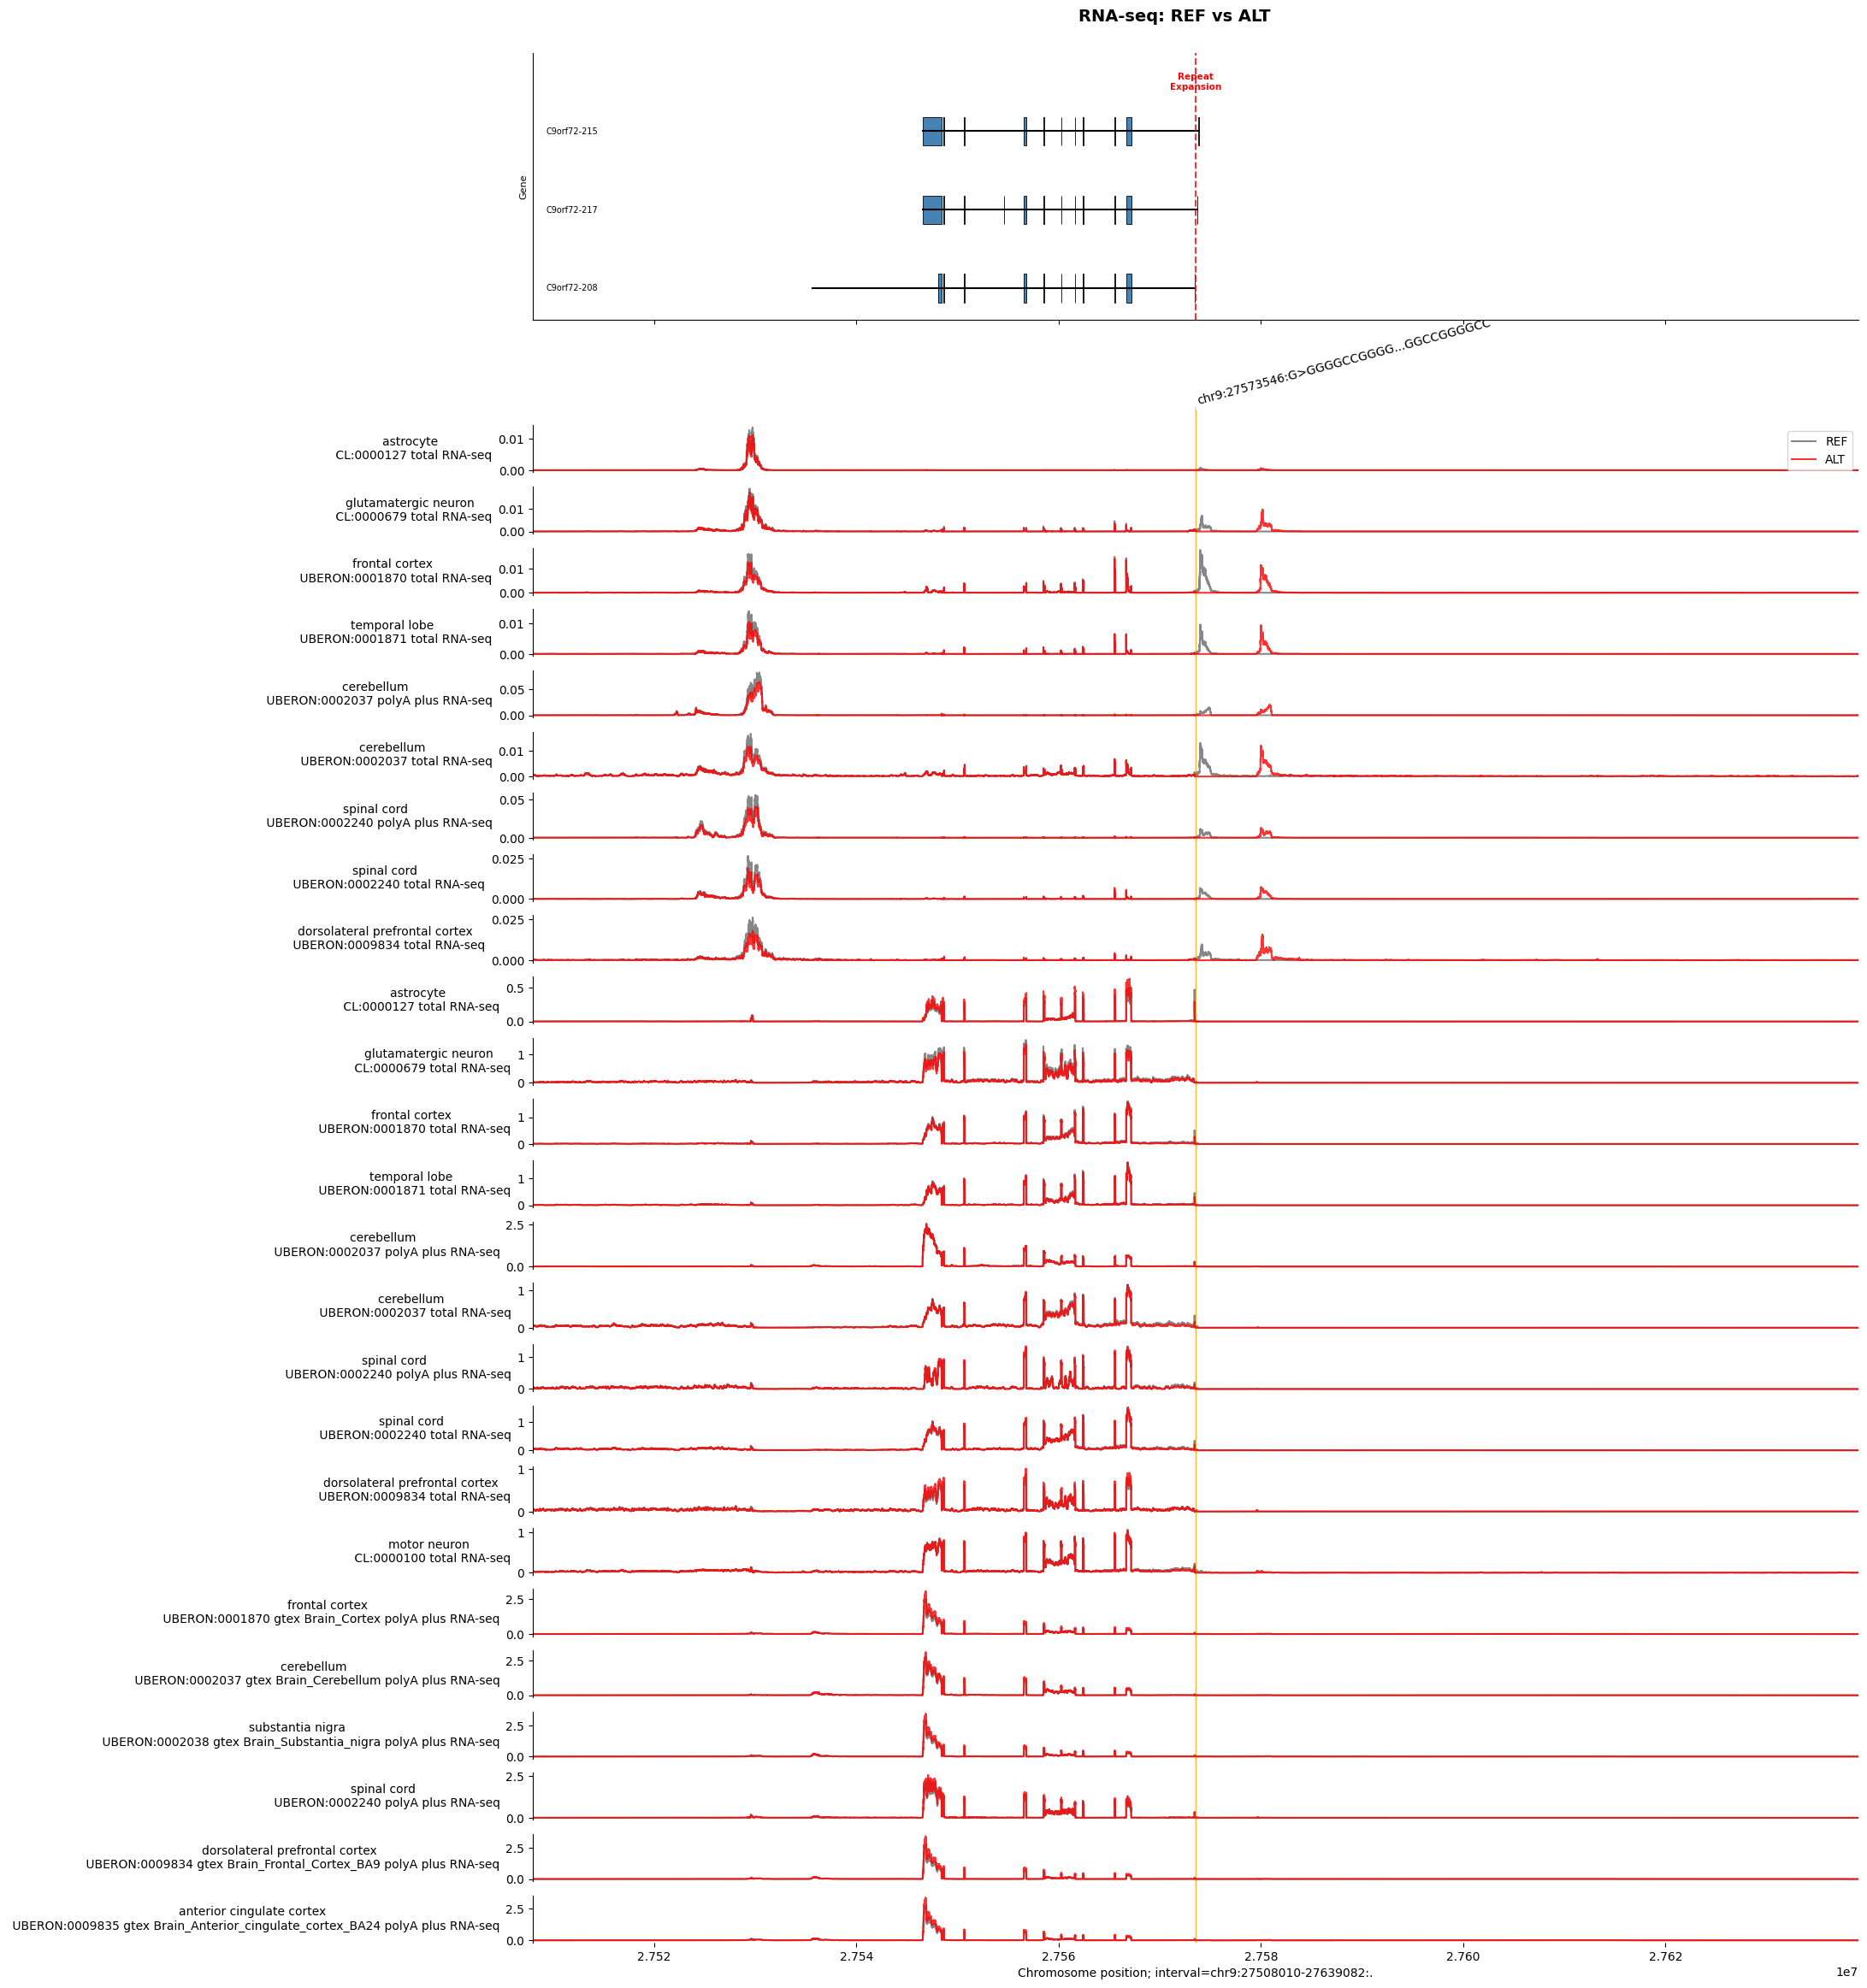

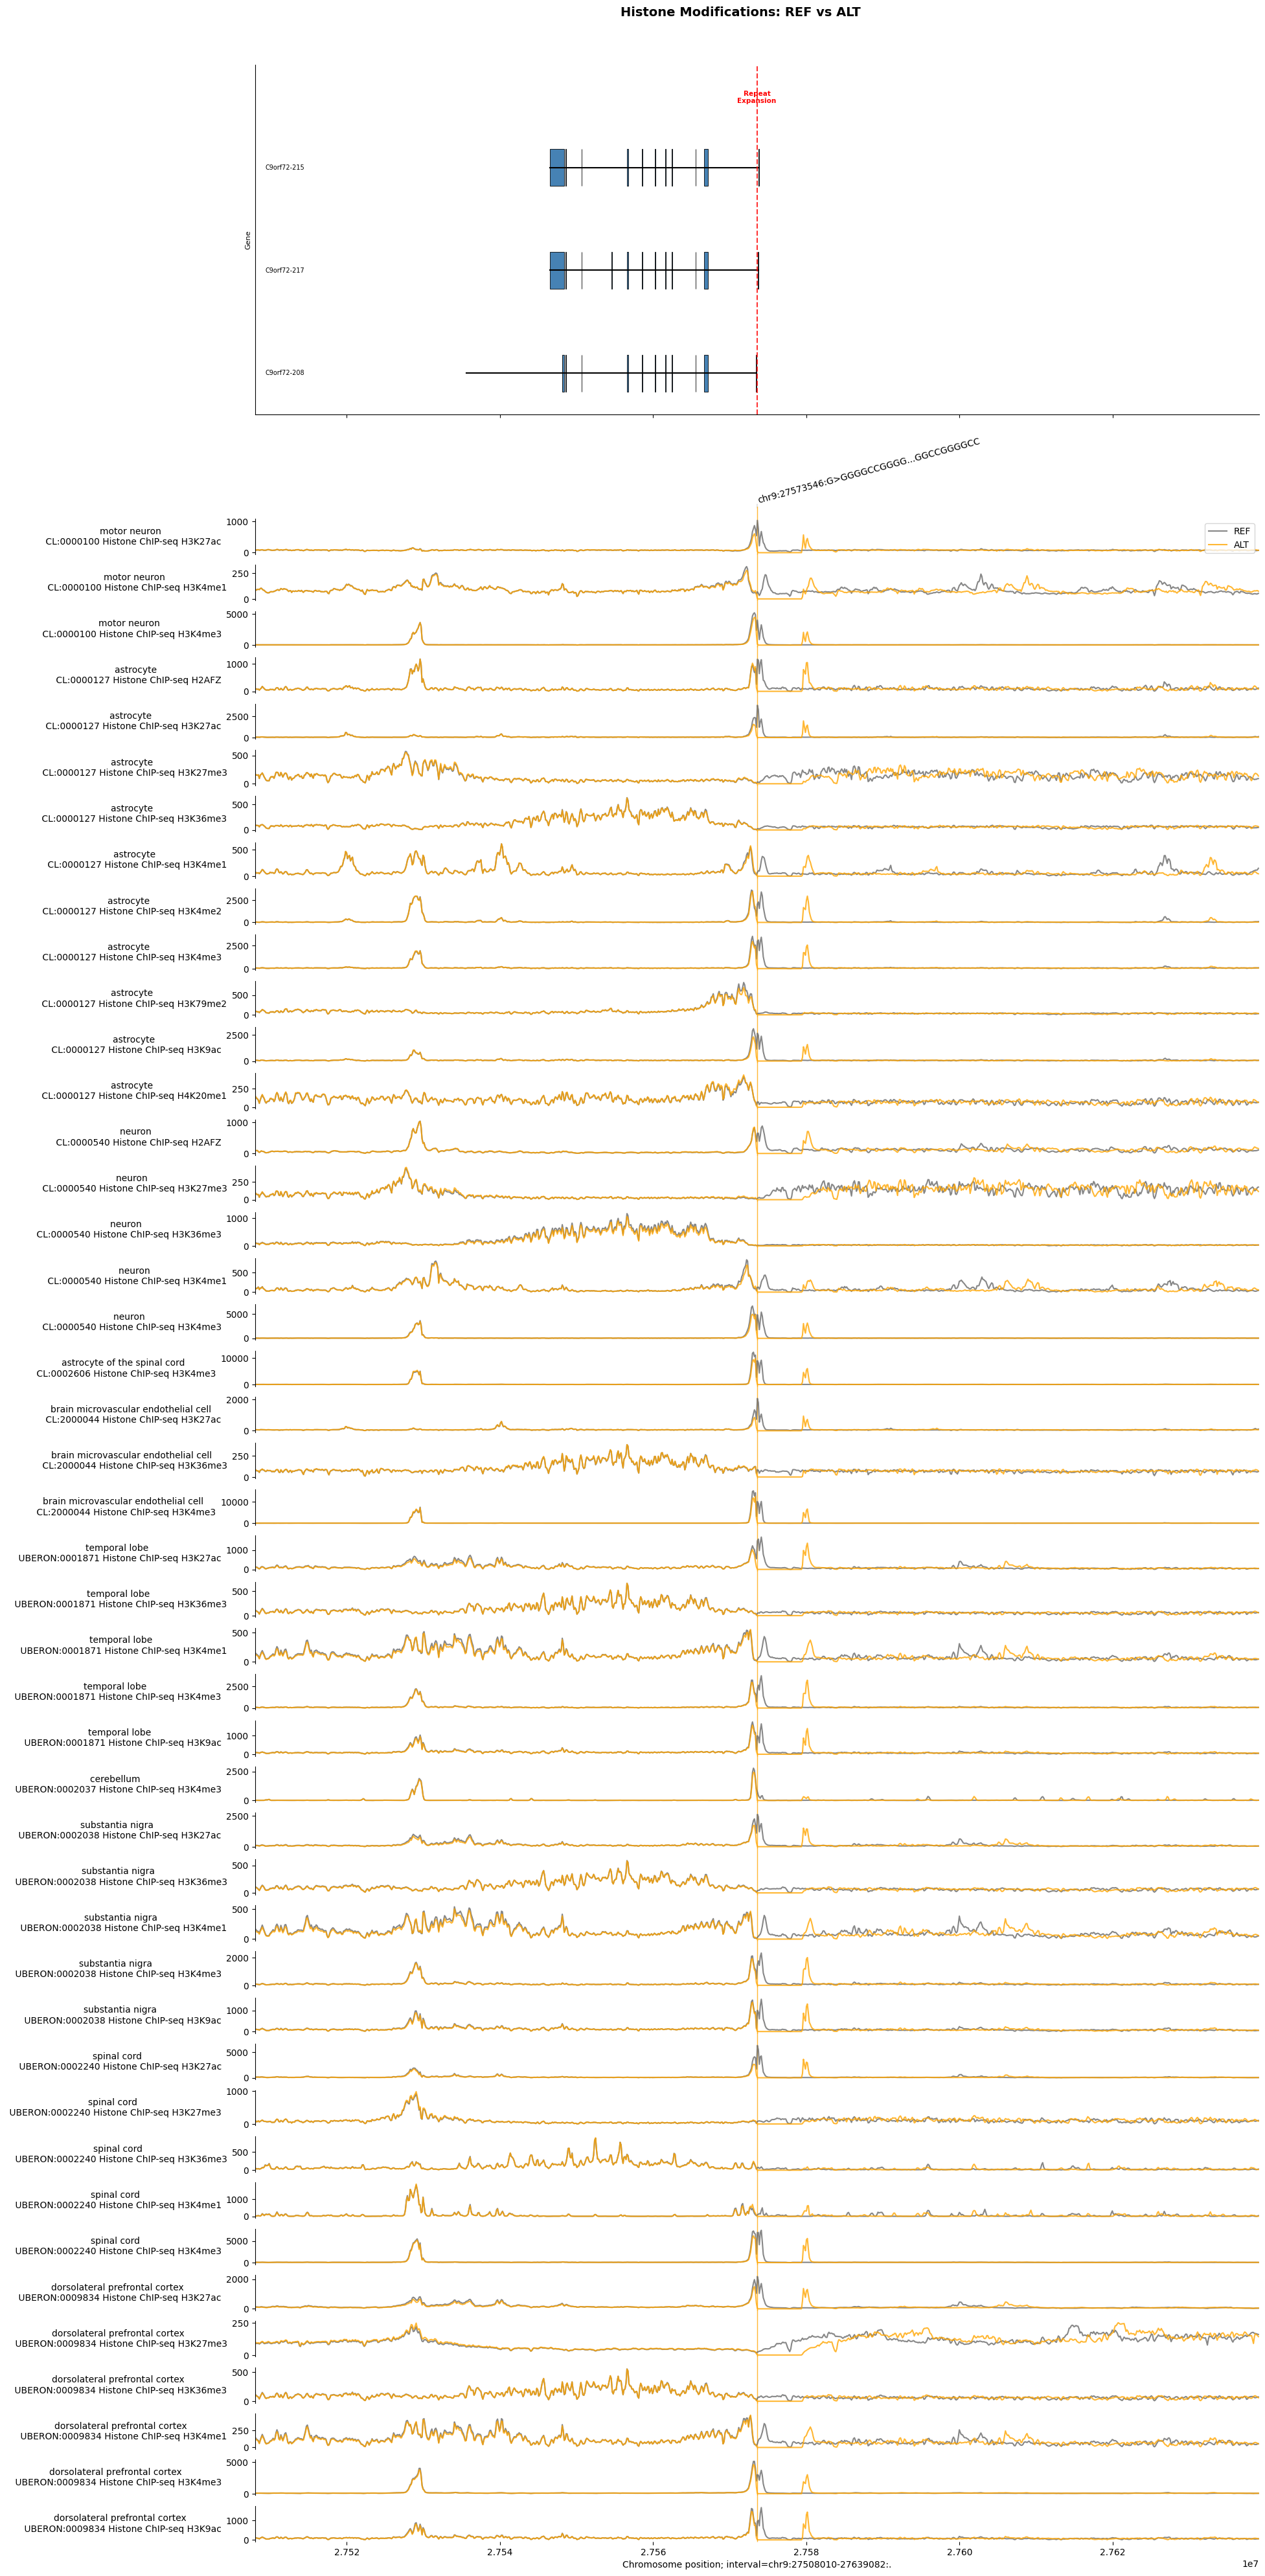

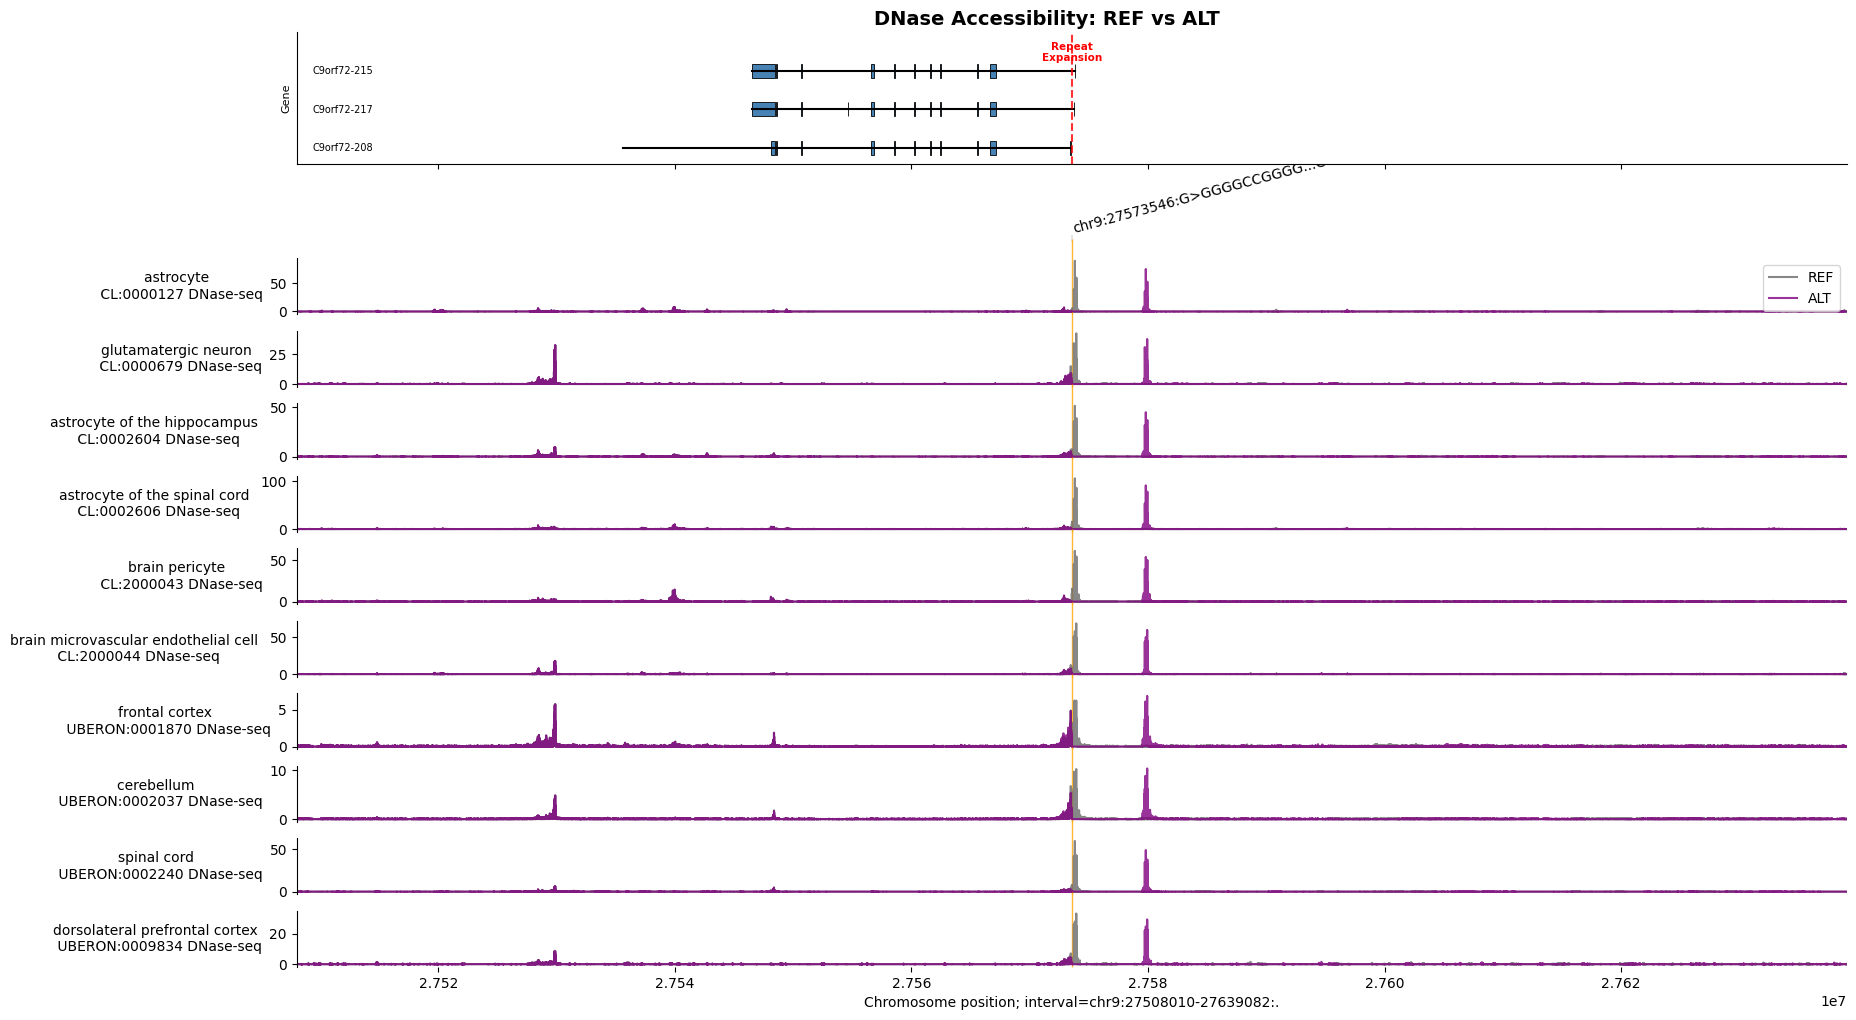

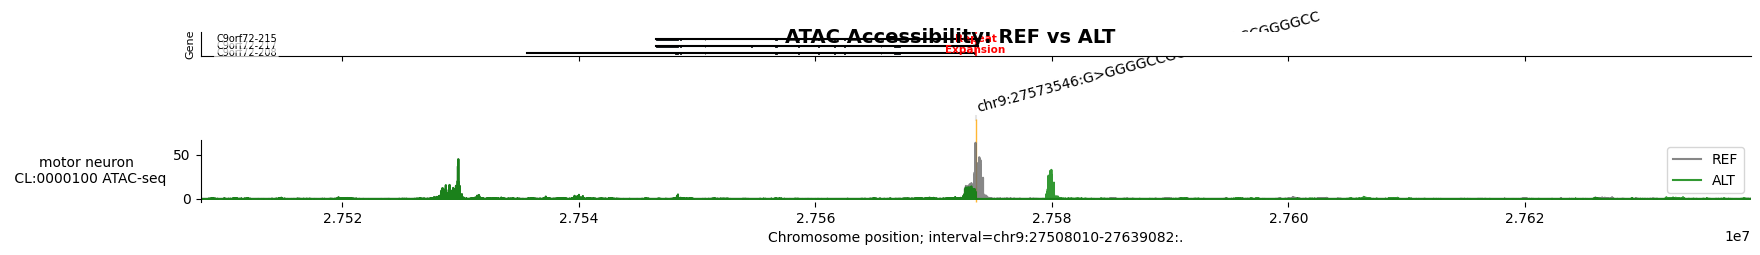

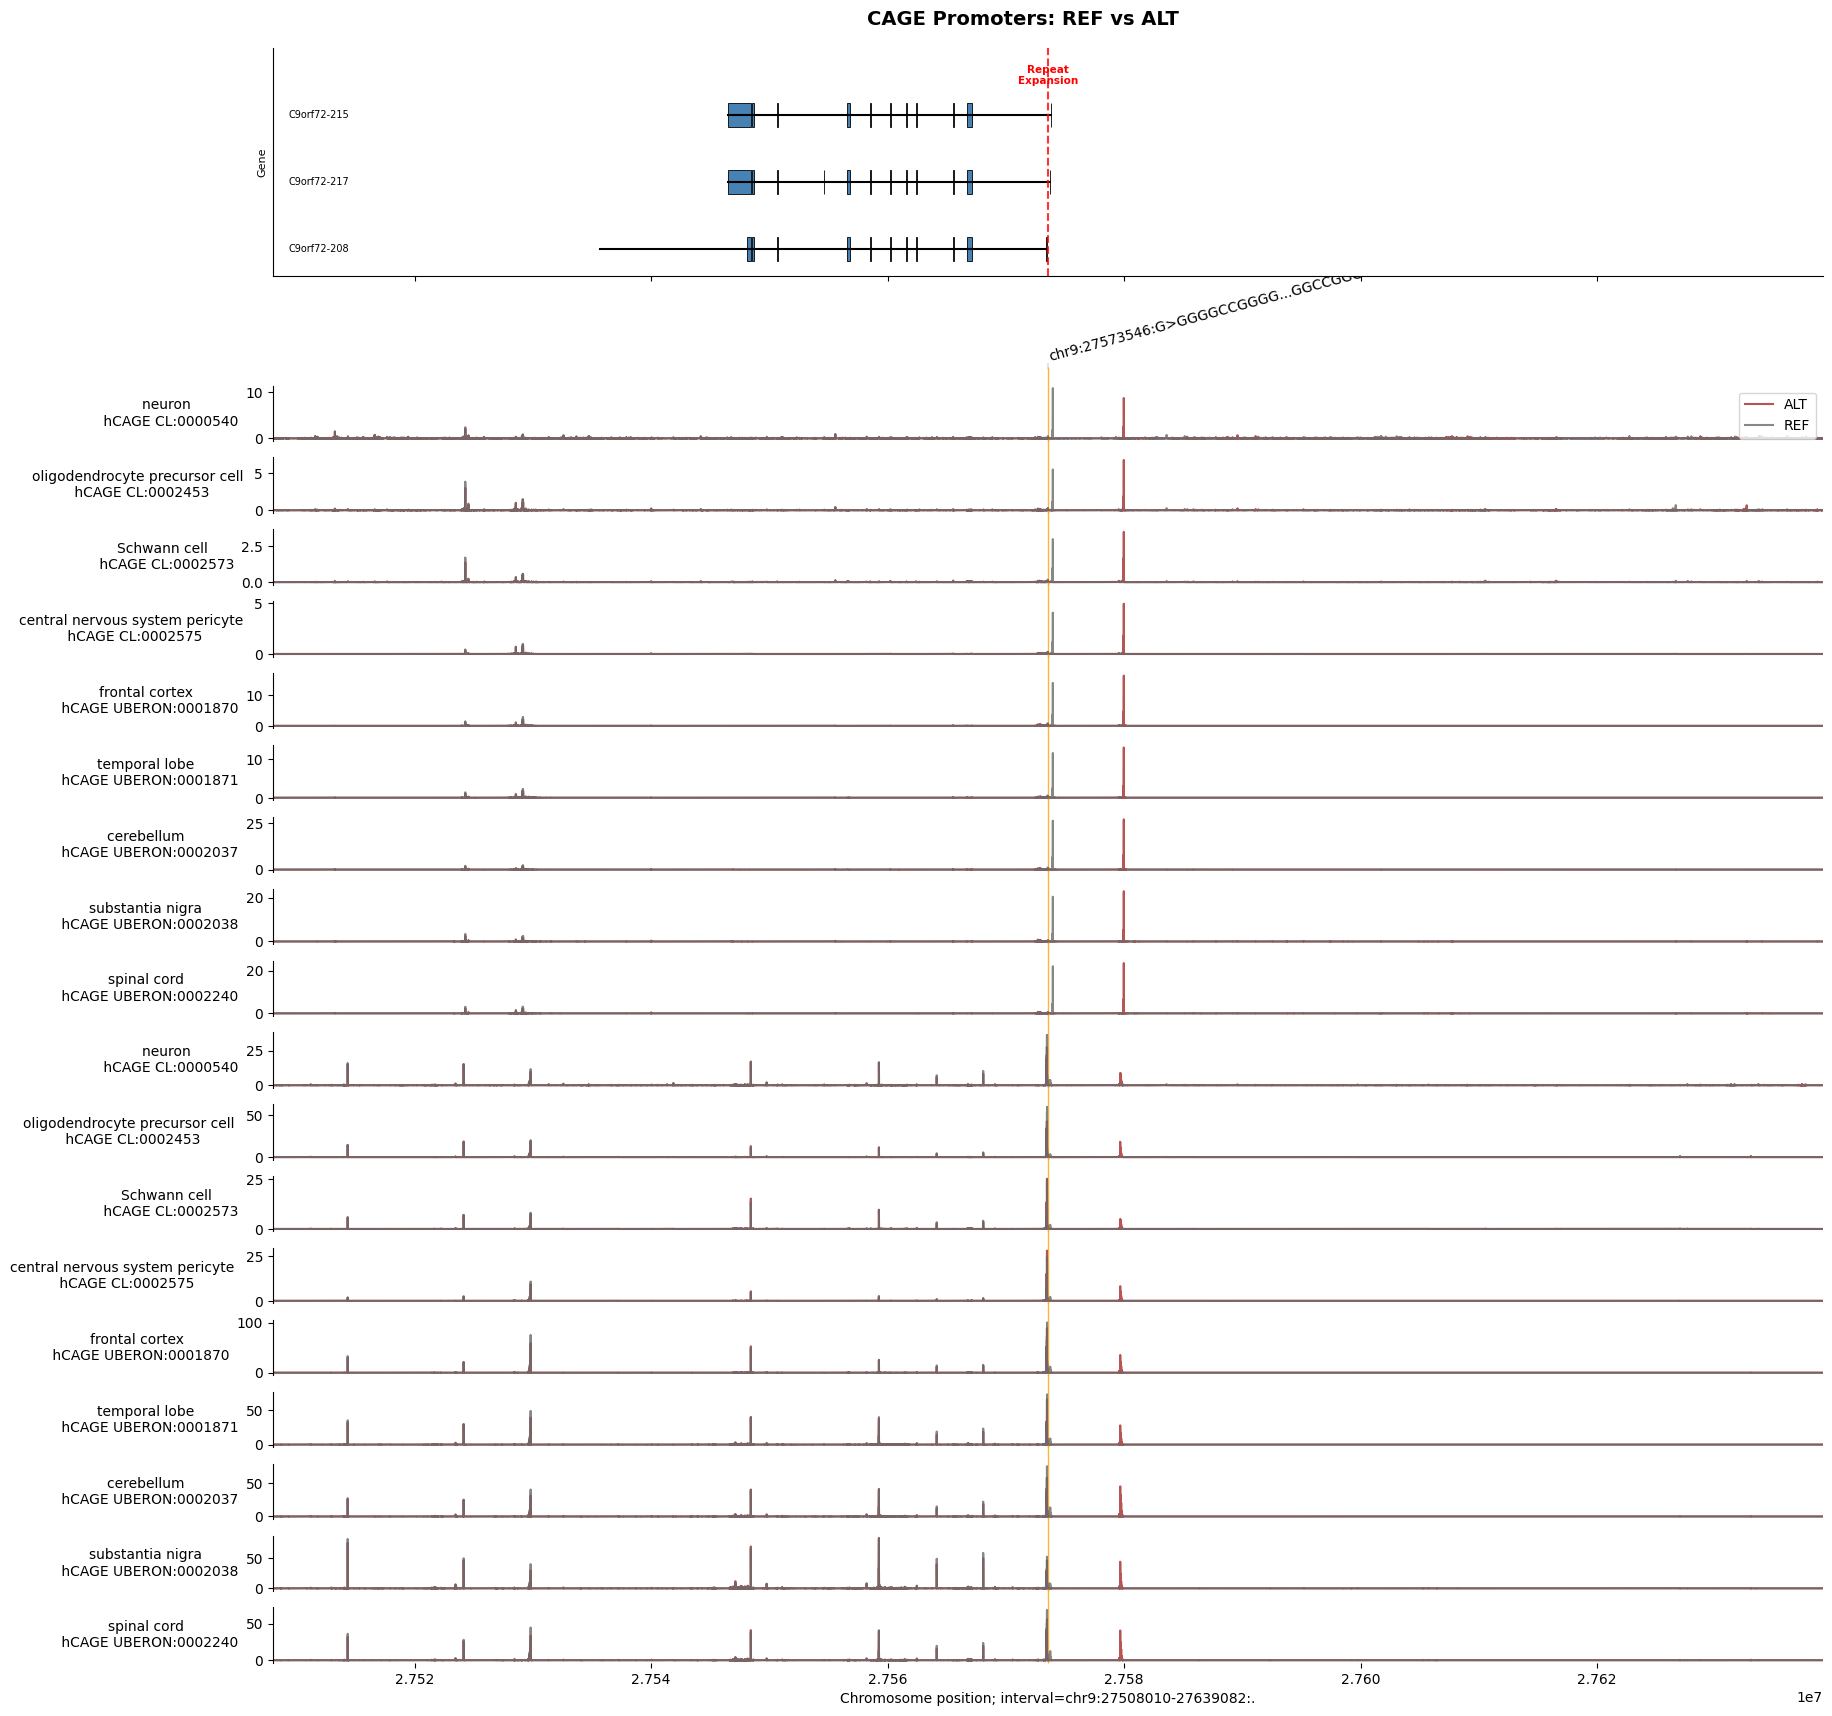

Contact map data not available or has incompatible dimensions for this tissue type


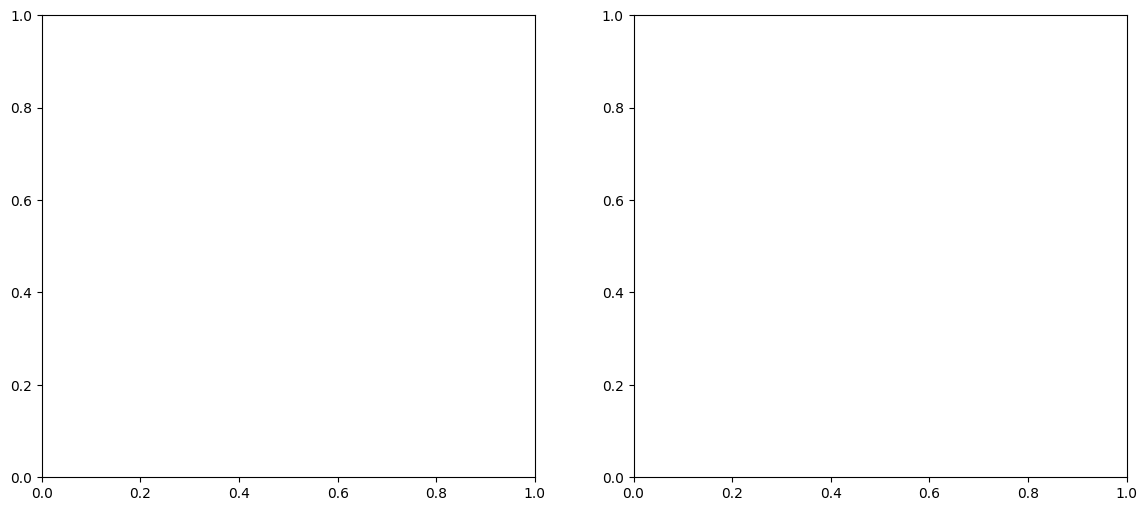

In [15]:
# Helpers: draw a compact gene model inside each track figure
def _draw_gene_model(ax_gene, interval, transcripts, variant, max_transcripts=3):
    y_offset = 0
    num_transcripts = min(max_transcripts, len(transcripts))

    for i, tx in enumerate(transcripts[:num_transcripts]):
        # Transcript line
        ax_gene.plot([tx['start'], tx['end']], [y_offset, y_offset], 'k-', linewidth=1.5)

        # Exons
        for exon in tx['exons']:
            ax_gene.add_patch(plt.Rectangle(
                (exon['start'], y_offset - 0.18),
                exon['end'] - exon['start'],
                0.36,
                facecolor='steelblue',
                edgecolor='black',
                linewidth=0.6
            ))

        # Label
        label_x = interval.start + (interval.end - interval.start) * 0.01
        tx_label = tx.get('transcript_name') or tx.get('transcript_id') or f"tx_{i+1}"
        ax_gene.text(
            label_x, y_offset, tx_label,
            va='center', ha='left', fontsize=7,
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='none', alpha=0.7)
        )
        y_offset += 1

    variant_pos = variant.position
    ax_gene.axvline(variant_pos, color='red', linestyle='--', alpha=0.8, linewidth=1.5)
    ax_gene.text(
        variant_pos, max(y_offset - 0.25, 0.4), 'Repeat\nExpansion',
        ha='center', va='top', fontsize=7.5, color='red', fontweight='bold'
    )

    ax_gene.set_xlim(interval.start, interval.end)
    ax_gene.set_ylim(-0.4, max(y_offset, 1))
    ax_gene.set_ylabel('Gene', fontsize=8)
    ax_gene.set_yticks([])
    ax_gene.tick_params(labelbottom=False)
    ax_gene.spines['right'].set_visible(False)
    ax_gene.spines['top'].set_visible(False)


def _add_gene_to_current_track_plot(interval, transcripts, variant):
    fig = plt.gcf()
    axes = fig.get_axes()
    if not axes:
        return

    # Use the first main axis created by plot_components
    ax_main = axes[0]
    main_pos = ax_main.get_position()

    # Create space at the top and add gene axis above the track axis
    fig.subplots_adjust(top=0.82)
    gene_height = 0.12
    gene_bottom = min(0.84, main_pos.y1 + 0.02)
    ax_gene = fig.add_axes([main_pos.x0, gene_bottom, main_pos.width, gene_height], sharex=ax_main)

    _draw_gene_model(ax_gene, interval, transcripts, variant)


# RNA-seq overlay + gene model
plot_components.plot(
    [
        plot_components.OverlaidTracks(
            tdata={
                'REF': variant_output.reference.rna_seq,
                'ALT': variant_output.alternate.rna_seq,
            },
            colors={'REF': 'dimgrey', 'ALT': 'red'},
            ylabel_template='{biosample_name} \n {name}',
        ),
    ],
    interval=variant_output.reference.rna_seq.interval,
    annotations=[plot_components.VariantAnnotation([variant], alpha=0.8)],
)
_add_gene_to_current_track_plot(variant_output.reference.rna_seq.interval, transcripts, variant)
plt.suptitle('RNA-seq: REF vs ALT', fontsize=14, fontweight='bold')
plt.show()

# ChIP-Histone overlay + gene model
plot_components.plot(
    [
        plot_components.OverlaidTracks(
            tdata={
                'REF': variant_output.reference.chip_histone,
                'ALT': variant_output.alternate.chip_histone,
            },
            colors={'REF': 'dimgrey', 'ALT': 'orange'},
            ylabel_template='{biosample_name} \n {name}',
        ),
    ],
    interval=variant_output.reference.chip_histone.interval,
    annotations=[plot_components.VariantAnnotation([variant], alpha=0.8)],
)
_add_gene_to_current_track_plot(variant_output.reference.chip_histone.interval, transcripts, variant)
plt.suptitle('Histone Modifications: REF vs ALT', fontsize=14, fontweight='bold')
plt.show()

# DNase overlay + gene model
plot_components.plot(
    [
        plot_components.OverlaidTracks(
            tdata={
                'REF': variant_output.reference.dnase,
                'ALT': variant_output.alternate.dnase,
            },
            colors={'REF': 'dimgrey', 'ALT': 'purple'},
            ylabel_template='{biosample_name} \n {name}',
        ),
    ],
    interval=variant_output.reference.dnase.interval,
    annotations=[plot_components.VariantAnnotation([variant], alpha=0.8)],
)
_add_gene_to_current_track_plot(variant_output.reference.dnase.interval, transcripts, variant)
plt.suptitle('DNase Accessibility: REF vs ALT', fontsize=14, fontweight='bold')
plt.show()

# ATAC overlay + gene model
plot_components.plot(
    [
        plot_components.OverlaidTracks(
            tdata={
                'REF': variant_output.reference.atac,
                'ALT': variant_output.alternate.atac,
            },
            colors={'REF': 'dimgrey', 'ALT': 'green'},
            ylabel_template='{biosample_name} \n {name}',
        ),
    ],
    interval=variant_output.reference.atac.interval,
    annotations=[plot_components.VariantAnnotation([variant], alpha=0.8)],
)
_add_gene_to_current_track_plot(variant_output.reference.atac.interval, transcripts, variant)
plt.suptitle('ATAC Accessibility: REF vs ALT', fontsize=14, fontweight='bold')
plt.show()

# CAGE overlay + gene model
plot_components.plot(
    [
        plot_components.OverlaidTracks(
            tdata={
                'REF': variant_output.reference.cage,
                'ALT': variant_output.alternate.cage,
            },
            colors={'REF': 'dimgrey', 'ALT': 'brown'},
            ylabel_template='{biosample_name} \n {name}',
        ),
    ],
    interval=variant_output.reference.cage.interval,
    annotations=[plot_components.VariantAnnotation([variant], alpha=0.8)],
)
_add_gene_to_current_track_plot(variant_output.reference.cage.interval, transcripts, variant)
plt.suptitle('CAGE Promoters: REF vs ALT', fontsize=14, fontweight='bold')
plt.show()

# Contact maps side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Check if contact maps have valid data
contact_ref_values = variant_output.reference.contact_maps.values
contact_alt_values = variant_output.alternate.contact_maps.values

if contact_ref_values.ndim == 3 and contact_ref_values.shape[2] > 0:
    contact_ref_2d = np.squeeze(contact_ref_values)
    contact_alt_2d = np.squeeze(contact_alt_values)

    im0 = axes[0].imshow(contact_ref_2d, cmap='RdBu_r', aspect='auto', origin='lower')
    axes[0].set_title('REF Contact Map', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Position')
    axes[0].set_ylabel('Position')
    plt.colorbar(im0, ax=axes[0], fraction=0.046)

    im1 = axes[1].imshow(contact_alt_2d, cmap='RdBu_r', aspect='auto', origin='lower')
    axes[1].set_title('ALT Contact Map', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Position')
    axes[1].set_ylabel('Position')
    plt.colorbar(im1, ax=axes[1], fraction=0.046)

    fig.suptitle('3D Chromatin Contact Maps: REF vs ALT', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
elif contact_ref_values.ndim == 2:
    im0 = axes[0].imshow(contact_ref_values, cmap='RdBu_r', aspect='auto', origin='lower')
    axes[0].set_title('REF Contact Map', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Position')
    axes[0].set_ylabel('Position')
    plt.colorbar(im0, ax=axes[0], fraction=0.046)

    im1 = axes[1].imshow(contact_alt_values, cmap='RdBu_r', aspect='auto', origin='lower')
    axes[1].set_title('ALT Contact Map', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Position')
    axes[1].set_ylabel('Position')
    plt.colorbar(im1, ax=axes[1], fraction=0.046)

    fig.suptitle('3D Chromatin Contact Maps: REF vs ALT', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print("Contact map data not available or has incompatible dimensions for this tissue type")

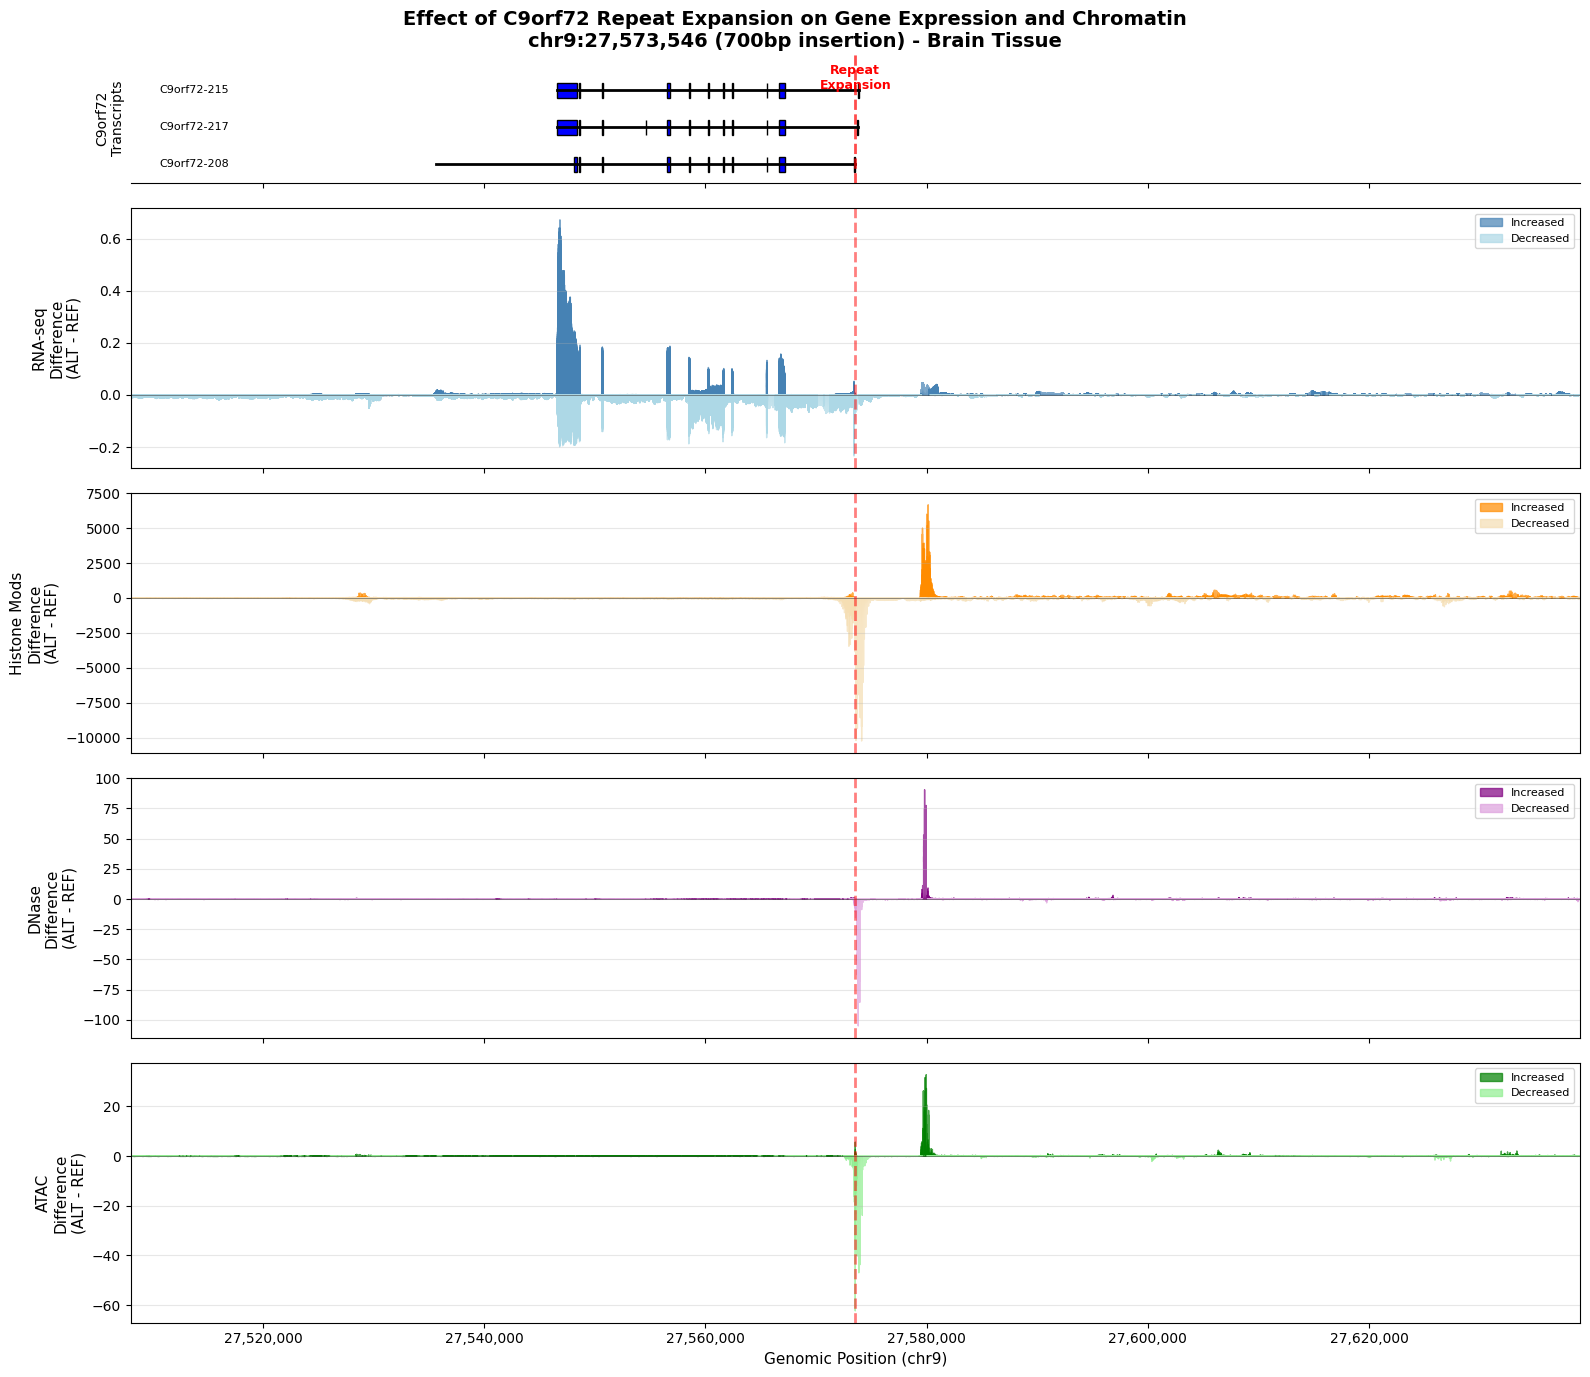

In [16]:
# Cell 6: Comprehensive Multi-Panel Plot


# Create figure with multiple subplots (5 tracks: gene annotation + RNA-seq + Histone + DNase + ATAC)
fig, axes = plt.subplots(5, 1, figsize=(16, 14), gridspec_kw={'height_ratios': [1, 2, 2, 2, 2]})

# Get the interval for plotting
plot_interval = variant_output.reference.rna_seq.interval

# --- Panel 1: Manual gene annotation ---
ax_gene = axes[0]
y_offset = 0
num_transcripts = min(3, len(transcripts))  # Show first 3 transcripts

for i, tx in enumerate(transcripts[:num_transcripts]):
    # Draw transcript line
    ax_gene.plot([tx['start'], tx['end']], [y_offset, y_offset], 'k-', linewidth=2)
    
    # Draw exons as thick boxes
    for exon in tx['exons']:
        ax_gene.add_patch(plt.Rectangle(
            (exon['start'], y_offset - 0.2), 
            exon['end'] - exon['start'], 
            0.4, 
            facecolor='blue', 
            edgecolor='black'
        ))
    
    # Add transcript label (inside the plot area, on the left)
    label_x = plot_interval.start + (plot_interval.end - plot_interval.start) * 0.02
    ax_gene.text(label_x, y_offset, tx['transcript_name'], 
                va='center', ha='left', fontsize=8, 
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='none', alpha=0.7))
    y_offset += 1

ax_gene.set_xlim(plot_interval.start, plot_interval.end)
ax_gene.set_ylim(-0.5, max(y_offset, 1))
ax_gene.set_ylabel('C9orf72\nTranscripts', fontsize=10)
ax_gene.set_yticks([])
ax_gene.spines['left'].set_visible(False)
ax_gene.spines['right'].set_visible(False)
ax_gene.spines['top'].set_visible(False)
ax_gene.tick_params(labelbottom=False)

# Add variant marker
variant_pos = variant.position
ax_gene.axvline(variant_pos, color='red', linestyle='--', alpha=0.7, linewidth=2)
ax_gene.text(variant_pos, max(y_offset - 0.3, 0.5), 'Repeat\nExpansion', 
            ha='center', va='top', fontsize=9, color='red', fontweight='bold')

# --- Panel 2: RNA-seq differences ---
ax_rna = axes[1]
rna_ref = variant_output.reference.rna_seq.filter_to_nonpositive_strand()
rna_alt = variant_output.alternate.rna_seq.filter_to_nonpositive_strand()

# Get the values and create position array
if hasattr(rna_ref, 'tracks') and rna_ref.tracks:
    # Multi-track: sum all tracks for overall effect
    ref_values = np.sum([track.values.flatten() for track in rna_ref.tracks], axis=0)
    alt_values = np.sum([track.values.flatten() for track in rna_alt.tracks], axis=0)
else:
    # Single track
    ref_values = rna_ref.values.flatten()
    alt_values = rna_alt.values.flatten()

diff_values = alt_values - ref_values
positions = np.linspace(rna_ref.interval.start, rna_ref.interval.end, len(diff_values))

# Plot as filled area
ax_rna.fill_between(positions, 0, diff_values, 
                     where=(diff_values >= 0), alpha=0.7, color='steelblue', 
                     label='Increased', interpolate=True)
ax_rna.fill_between(positions, 0, diff_values, 
                     where=(diff_values < 0), alpha=0.7, color='lightblue', 
                     label='Decreased', interpolate=True)

ax_rna.axhline(0, color='black', linestyle='-', linewidth=0.5, alpha=0.5)
ax_rna.axvline(variant_pos, color='red', linestyle='--', alpha=0.5, linewidth=2)
ax_rna.set_xlim(rna_ref.interval.start, rna_ref.interval.end)
ax_rna.set_ylabel('RNA-seq\nDifference\n(ALT - REF)', fontsize=11)
ax_rna.tick_params(labelbottom=False)
ax_rna.grid(True, alpha=0.3, axis='y')
ax_rna.legend(loc='upper right', fontsize=8)

# --- Panel 3: ChIP-Histone differences ---
ax_chip = axes[2]
chip_ref = variant_output.reference.chip_histone.filter_to_nonpositive_strand()
chip_alt = variant_output.alternate.chip_histone.filter_to_nonpositive_strand()

# Get the values
if hasattr(chip_alt, 'tracks') and chip_alt.tracks:
    # Multi-track: sum all tracks for overall effect
    ref_values = np.sum([track.values.flatten() for track in chip_ref.tracks], axis=0)
    alt_values = np.sum([track.values.flatten() for track in chip_alt.tracks], axis=0)
else:
    # Single track
    ref_values = chip_ref.values.flatten()
    alt_values = chip_alt.values.flatten()

diff_values = alt_values - ref_values
positions = np.linspace(chip_ref.interval.start, chip_ref.interval.end, len(diff_values))

# Plot as bars/filled area
ax_chip.fill_between(positions, 0, diff_values, 
                      where=(diff_values >= 0), alpha=0.7, color='darkorange', 
                      label='Increased', interpolate=True)
ax_chip.fill_between(positions, 0, diff_values, 
                      where=(diff_values < 0), alpha=0.7, color='wheat', 
                      label='Decreased', interpolate=True)

ax_chip.axhline(0, color='black', linestyle='-', linewidth=0.5, alpha=0.5)
ax_chip.axvline(variant_pos, color='red', linestyle='--', alpha=0.5, linewidth=2)
ax_chip.set_xlim(chip_ref.interval.start, chip_ref.interval.end)
ax_chip.set_ylabel('Histone Mods\nDifference\n(ALT - REF)', fontsize=11)
ax_chip.tick_params(labelbottom=False)
ax_chip.grid(True, alpha=0.3, axis='y')
ax_chip.legend(loc='upper right', fontsize=8)

# --- Panel 4: DNase differences ---
ax_dnase = axes[3]
dnase_ref = variant_output.reference.dnase.filter_to_nonpositive_strand()
dnase_alt = variant_output.alternate.dnase.filter_to_nonpositive_strand()

# Get the values
if hasattr(dnase_alt, 'tracks') and dnase_alt.tracks:
    ref_values = np.sum([track.values.flatten() for track in dnase_ref.tracks], axis=0)
    alt_values = np.sum([track.values.flatten() for track in dnase_alt.tracks], axis=0)
else:
    ref_values = dnase_ref.values.flatten()
    alt_values = dnase_alt.values.flatten()

diff_values = alt_values - ref_values
positions = np.linspace(dnase_ref.interval.start, dnase_ref.interval.end, len(diff_values))

ax_dnase.fill_between(positions, 0, diff_values, 
                       where=(diff_values >= 0), alpha=0.7, color='purple', 
                       label='Increased', interpolate=True)
ax_dnase.fill_between(positions, 0, diff_values, 
                       where=(diff_values < 0), alpha=0.7, color='plum', 
                       label='Decreased', interpolate=True)

ax_dnase.axhline(0, color='black', linestyle='-', linewidth=0.5, alpha=0.5)
ax_dnase.axvline(variant_pos, color='red', linestyle='--', alpha=0.5, linewidth=2)
ax_dnase.set_xlim(dnase_ref.interval.start, dnase_ref.interval.end)
ax_dnase.set_ylabel('DNase\nDifference\n(ALT - REF)', fontsize=11)
ax_dnase.tick_params(labelbottom=False)
ax_dnase.grid(True, alpha=0.3, axis='y')
ax_dnase.legend(loc='upper right', fontsize=8)

# --- Panel 5: ATAC differences ---
ax_atac = axes[4]
atac_ref = variant_output.reference.atac.filter_to_nonpositive_strand()
atac_alt = variant_output.alternate.atac.filter_to_nonpositive_strand()

# Get the values
if hasattr(atac_alt, 'tracks') and atac_alt.tracks:
    ref_values = np.sum([track.values.flatten() for track in atac_ref.tracks], axis=0)
    alt_values = np.sum([track.values.flatten() for track in atac_alt.tracks], axis=0)
else:
    ref_values = atac_ref.values.flatten()
    alt_values = atac_alt.values.flatten()

diff_values = alt_values - ref_values
positions = np.linspace(atac_ref.interval.start, atac_ref.interval.end, len(diff_values))

ax_atac.fill_between(positions, 0, diff_values, 
                      where=(diff_values >= 0), alpha=0.7, color='green', 
                      label='Increased', interpolate=True)
ax_atac.fill_between(positions, 0, diff_values, 
                      where=(diff_values < 0), alpha=0.7, color='lightgreen', 
                      label='Decreased', interpolate=True)

ax_atac.axhline(0, color='black', linestyle='-', linewidth=0.5, alpha=0.5)
ax_atac.axvline(variant_pos, color='red', linestyle='--', alpha=0.5, linewidth=2)
ax_atac.set_xlim(atac_ref.interval.start, atac_ref.interval.end)
ax_atac.set_ylabel('ATAC\nDifference\n(ALT - REF)', fontsize=11)
ax_atac.set_xlabel('Genomic Position (chr9)', fontsize=11)
ax_atac.grid(True, alpha=0.3, axis='y')
ax_atac.legend(loc='upper right', fontsize=8)

# Format x-axis with commas
ax_atac.ticklabel_format(style='plain', axis='x')
ax_atac.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x):,}'))

fig.suptitle(f'Effect of C9orf72 Repeat Expansion on Gene Expression and Chromatin\n'
             f'{variant.chromosome}:{variant.position:,} (700bp insertion) - Brain Tissue',
             fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

## Comprehensive Multi-Panel Plot

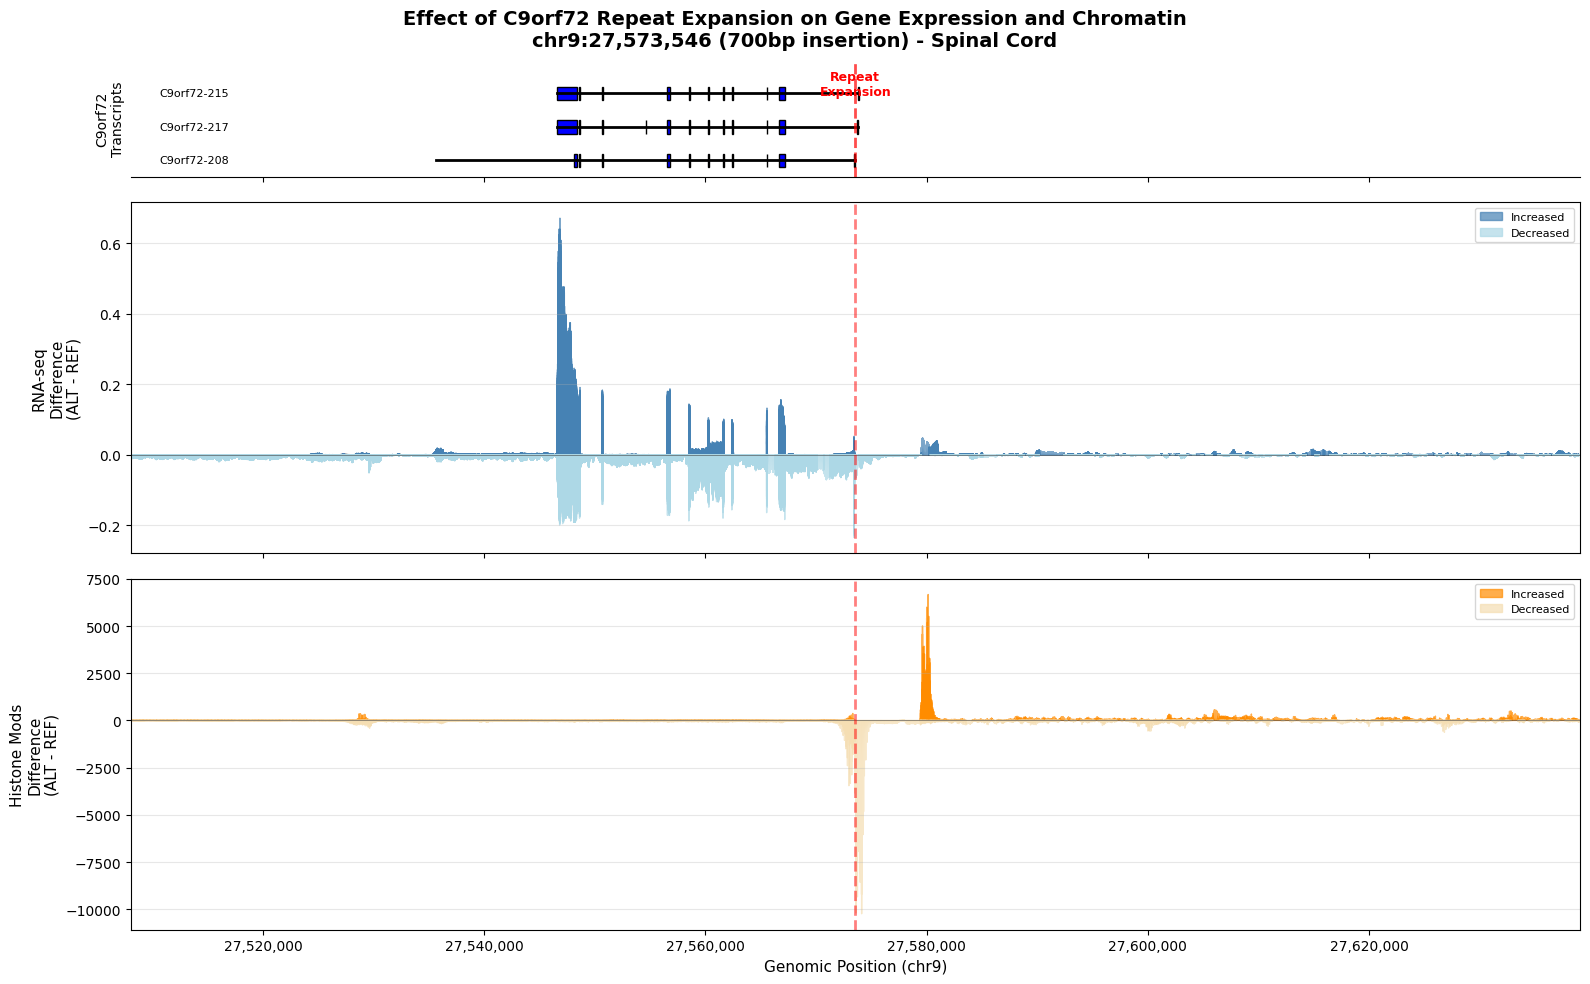

In [17]:

# Create figure with multiple subplots
fig, axes = plt.subplots(3, 1, figsize=(16, 10), gridspec_kw={'height_ratios': [1, 3, 3]})

# Get the interval for plotting
plot_interval = variant_output.reference.rna_seq.interval

# --- Panel 1: Manual gene annotation ---
ax_gene = axes[0]
y_offset = 0
num_transcripts = min(3, len(transcripts))  # Show first 3 transcripts

for i, tx in enumerate(transcripts[:num_transcripts]):
    # Draw transcript line
    ax_gene.plot([tx['start'], tx['end']], [y_offset, y_offset], 'k-', linewidth=2)
    
    # Draw exons as thick boxes
    for exon in tx['exons']:
        ax_gene.add_patch(plt.Rectangle(
            (exon['start'], y_offset - 0.2), 
            exon['end'] - exon['start'], 
            0.4, 
            facecolor='blue', 
            edgecolor='black'
        ))
    
    # Add transcript label (inside the plot area, on the left)
    label_x = plot_interval.start + (plot_interval.end - plot_interval.start) * 0.02
    ax_gene.text(label_x, y_offset, tx['transcript_name'], 
                va='center', ha='left', fontsize=8, 
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='none', alpha=0.7))
    y_offset += 1

ax_gene.set_xlim(plot_interval.start, plot_interval.end)
ax_gene.set_ylim(-0.5, max(y_offset, 1))
ax_gene.set_ylabel('C9orf72\nTranscripts', fontsize=10)
ax_gene.set_yticks([])
ax_gene.spines['left'].set_visible(False)
ax_gene.spines['right'].set_visible(False)
ax_gene.spines['top'].set_visible(False)
ax_gene.tick_params(labelbottom=False)

# Add variant marker
variant_pos = variant.position
ax_gene.axvline(variant_pos, color='red', linestyle='--', alpha=0.7, linewidth=2)
ax_gene.text(variant_pos, max(y_offset - 0.3, 0.5), 'Repeat\nExpansion', 
            ha='center', va='top', fontsize=9, color='red', fontweight='bold')

# --- Panel 2: RNA-seq differences ---
ax_rna = axes[1]
rna_ref = variant_output.reference.rna_seq.filter_to_nonpositive_strand()
rna_alt = variant_output.alternate.rna_seq.filter_to_nonpositive_strand()

# Get the values and create position array
if hasattr(rna_ref, 'tracks') and rna_ref.tracks:
    # Multi-track: sum all tracks for overall effect
    ref_values = np.sum([track.values.flatten() for track in rna_ref.tracks], axis=0)
    alt_values = np.sum([track.values.flatten() for track in rna_alt.tracks], axis=0)
else:
    # Single track
    ref_values = rna_ref.values.flatten()
    alt_values = rna_alt.values.flatten()

diff_values = alt_values - ref_values
positions = np.linspace(rna_ref.interval.start, rna_ref.interval.end, len(diff_values))

# Plot as filled area
ax_rna.fill_between(positions, 0, diff_values, 
                     where=(diff_values >= 0), alpha=0.7, color='steelblue', 
                     label='Increased', interpolate=True)
ax_rna.fill_between(positions, 0, diff_values, 
                     where=(diff_values < 0), alpha=0.7, color='lightblue', 
                     label='Decreased', interpolate=True)

ax_rna.axhline(0, color='black', linestyle='-', linewidth=0.5, alpha=0.5)
ax_rna.axvline(variant_pos, color='red', linestyle='--', alpha=0.5, linewidth=2)
ax_rna.set_xlim(rna_ref.interval.start, rna_ref.interval.end)
ax_rna.set_ylabel('RNA-seq\nDifference\n(ALT - REF)', fontsize=11)
ax_rna.tick_params(labelbottom=False)
ax_rna.grid(True, alpha=0.3, axis='y')
ax_rna.legend(loc='upper right', fontsize=8)

# --- Panel 3: ChIP-Histone differences ---
ax_chip = axes[2]
chip_ref = variant_output.reference.chip_histone.filter_to_nonpositive_strand()
chip_alt = variant_output.alternate.chip_histone.filter_to_nonpositive_strand()

# Get the values
if hasattr(chip_alt, 'tracks') and chip_alt.tracks:
    # Multi-track: sum all tracks for overall effect
    ref_values = np.sum([track.values.flatten() for track in chip_ref.tracks], axis=0)
    alt_values = np.sum([track.values.flatten() for track in chip_alt.tracks], axis=0)
else:
    # Single track
    ref_values = chip_ref.values.flatten()
    alt_values = chip_alt.values.flatten()

diff_values = alt_values - ref_values
positions = np.linspace(chip_ref.interval.start, chip_ref.interval.end, len(diff_values))

# Plot as bars/filled area
ax_chip.fill_between(positions, 0, diff_values, 
                      where=(diff_values >= 0), alpha=0.7, color='darkorange', 
                      label='Increased', interpolate=True)
ax_chip.fill_between(positions, 0, diff_values, 
                      where=(diff_values < 0), alpha=0.7, color='wheat', 
                      label='Decreased', interpolate=True)

ax_chip.axhline(0, color='black', linestyle='-', linewidth=0.5, alpha=0.5)
ax_chip.axvline(variant_pos, color='red', linestyle='--', alpha=0.5, linewidth=2)
ax_chip.set_xlim(chip_ref.interval.start, chip_ref.interval.end)
ax_chip.set_ylabel('Histone Mods\nDifference\n(ALT - REF)', fontsize=11)
ax_chip.set_xlabel('Genomic Position (chr9)', fontsize=11)
ax_chip.grid(True, alpha=0.3, axis='y')
ax_chip.legend(loc='upper right', fontsize=8)

# Format x-axis with commas
ax_chip.ticklabel_format(style='plain', axis='x')
ax_chip.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x):,}'))

fig.suptitle(f'Effect of C9orf72 Repeat Expansion on Gene Expression and Chromatin\n'
             f'{variant.chromosome}:{variant.position:,} (700bp insertion) - Spinal Cord',
             fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

In [10]:
# Visualize contact maps (3D chromatin structure)
# First, inspect the contact map structure
print("Contact map structure inspection:")
print(f"Reference contact_maps type: {type(variant_output.reference.contact_maps)}")
print(f"Reference contact_maps.values shape: {variant_output.reference.contact_maps.values.shape}")

# Extract contact map data properly
contact_ref_obj = variant_output.reference.contact_maps
contact_alt_obj = variant_output.alternate.contact_maps

# Check if we need to squeeze or reshape the data
contact_ref = contact_ref_obj.values
contact_alt = contact_alt_obj.values

print(f"Initial shapes - REF: {contact_ref.shape}, ALT: {contact_alt.shape}")

# Handle different possible shapes
if contact_ref.ndim == 3:
    # If shape is (N, M, 1) or (N, M, 0), we need to handle it
    if contact_ref.shape[2] == 0:
        print("Warning: Contact maps have empty third dimension. Skipping contact map visualization.")
        print("This might indicate the tissue/cell type doesn't have contact map data.")
    else:
        # Squeeze out singleton dimensions
        contact_ref = np.squeeze(contact_ref)
        contact_alt = np.squeeze(contact_alt)
        
        if contact_ref.ndim == 2 and contact_alt.ndim == 2:
            # Now we can plot
            fig, axes = plt.subplots(1, 3, figsize=(18, 5))
            
            # Reference contact map
            im0 = axes[0].imshow(contact_ref, cmap='RdBu_r', aspect='auto', origin='lower')
            axes[0].set_title('REF Contact Map', fontsize=14, fontweight='bold')
            axes[0].set_xlabel('Genomic Position')
            axes[0].set_ylabel('Genomic Position')
            plt.colorbar(im0, ax=axes[0], label='Contact Frequency', fraction=0.046)
            
            # Alternate contact map
            im1 = axes[1].imshow(contact_alt, cmap='RdBu_r', aspect='auto', origin='lower')
            axes[1].set_title('ALT Contact Map (with Repeat Expansion)', fontsize=14, fontweight='bold')
            axes[1].set_xlabel('Genomic Position')
            axes[1].set_ylabel('Genomic Position')
            plt.colorbar(im1, ax=axes[1], label='Contact Frequency', fraction=0.046)
            
            # Difference map (ALT - REF)
            diff_map = contact_alt - contact_ref
            diff_max = np.nanmax(np.abs(diff_map))
            if diff_max > 0:
                im2 = axes[2].imshow(diff_map, cmap='RdBu_r', aspect='auto', 
                                    vmin=-diff_max, vmax=diff_max, origin='lower')
            else:
                im2 = axes[2].imshow(diff_map, cmap='RdBu_r', aspect='auto', origin='lower')
            axes[2].set_title('Difference (ALT - REF)', fontsize=14, fontweight='bold')
            axes[2].set_xlabel('Genomic Position')
            axes[2].set_ylabel('Genomic Position')
            plt.colorbar(im2, ax=axes[2], label='Contact Difference', fraction=0.046)
            
            fig.suptitle('3D Chromatin Structure at C9orf72 Repeat Expansion', 
                        fontsize=16, fontweight='bold', y=1.02)
            plt.tight_layout()
            plt.show()
        else:
            print(f"After squeezing: REF shape {contact_ref.shape}, ALT shape {contact_alt.shape}")
            print("Cannot create 2D contact map visualization.")
else:
    print(f"Unexpected contact map dimension: {contact_ref.ndim}")



Contact map structure inspection:
Reference contact_maps type: <class 'alphagenome.data.track_data.TrackData'>
Reference contact_maps.values shape: (8, 8, 0)
Initial shapes - REF: (8, 8, 0), ALT: (8, 8, 0)
This might indicate the tissue/cell type doesn't have contact map data.


In [18]:
## Cell 8: Summary Statistics

# Summary statistics: quantify the changes
print("="*80)
print("VARIANT IMPACT SUMMARY AT C9orf72 REPEAT EXPANSION")
print("="*80)
print(f"\nVariant: {variant.chromosome}:{variant.position:,}")
print(f"  REF: {variant.reference_bases}")
print(f"  ALT: {variant.alternate_bases[:50]}... ({len(variant.alternate_bases)} bp)")
print(f"Location: Repeat expansion region (chr9:27,573,483-27,573,546)")
print(f"Gene: C9orf72 (MINUS strand)")
print(f"Tissue context: Brain (UBERON:0000955)")

# RNA-seq changes
rna_ref = variant_output.reference.rna_seq.filter_to_nonpositive_strand()
rna_alt = variant_output.alternate.rna_seq.filter_to_nonpositive_strand()
rna_diff = (rna_alt.values - rna_ref.values).flatten()

print(f"\n📊 RNA-seq Impact:")
if len(rna_diff) > 0:
    print(f"  Mean difference (ALT - REF): {np.nanmean(rna_diff):.4f}")
    print(f"  Max increase: {np.nanmax(rna_diff):.4f}")
    print(f"  Max decrease: {np.nanmin(rna_diff):.4f}")
    print(f"  Std deviation: {np.nanstd(rna_diff):.4f}")
else:
    print(f"  No data available for this tissue/cell type")

# ChIP Histone changes
chip_ref = variant_output.reference.chip_histone.filter_to_nonpositive_strand()
chip_alt = variant_output.alternate.chip_histone.filter_to_nonpositive_strand()

print(f"\n📊 Histone Modifications Impact:")
if hasattr(chip_alt, 'tracks') and chip_alt.tracks:
    print(f"  Number of histone marks analyzed: {len(chip_alt.tracks)}")
    for track in chip_alt.tracks:
        track_name = track.name
        ref_track = [t for t in chip_ref.tracks if t.name == track_name][0]
        diff_values = (track.values - ref_track.values).flatten()
        if len(diff_values) > 0:
            mean_diff = np.nanmean(diff_values)
            status = 'INCREASED' if mean_diff > 0.01 else 'DECREASED' if mean_diff < -0.01 else 'MINIMAL'
            print(f"  {track_name}: Mean Δ = {mean_diff:.4f} ({status})")
        else:
            print(f"  {track_name}: No data available")
else:
    diff_values = (chip_alt.values - chip_ref.values).flatten()
    if len(diff_values) > 0:
        mean_diff = np.nanmean(diff_values)
        status = 'INCREASED' if mean_diff > 0.01 else 'DECREASED' if mean_diff < -0.01 else 'MINIMAL'
        print(f"  Histone modifications: Mean Δ = {mean_diff:.4f} ({status})")
    else:
        print(f"  Histone modifications: No data available")

# DNase changes
dnase_ref = variant_output.reference.dnase.filter_to_nonpositive_strand()
dnase_alt = variant_output.alternate.dnase.filter_to_nonpositive_strand()
dnase_diff = (dnase_alt.values - dnase_ref.values).flatten()

print(f"\n📊 DNase Accessibility Impact:")
if len(dnase_diff) > 0:
    print(f"  Mean difference (ALT - REF): {np.nanmean(dnase_diff):.4f}")
    print(f"  Max increase: {np.nanmax(dnase_diff):.4f}")
    print(f"  Max decrease: {np.nanmin(dnase_diff):.4f}")
    print(f"  Std deviation: {np.nanstd(dnase_diff):.4f}")
else:
    print(f"  No data available for this tissue/cell type")

# ATAC changes
atac_ref = variant_output.reference.atac.filter_to_nonpositive_strand()
atac_alt = variant_output.alternate.atac.filter_to_nonpositive_strand()
atac_diff = (atac_alt.values - atac_ref.values).flatten()

print(f"\n📊 ATAC Accessibility Impact:")
if len(atac_diff) > 0:
    print(f"  Mean difference (ALT - REF): {np.nanmean(atac_diff):.4f}")
    print(f"  Max increase: {np.nanmax(atac_diff):.4f}")
    print(f"  Max decrease: {np.nanmin(atac_diff):.4f}")
    print(f"  Std deviation: {np.nanstd(atac_diff):.4f}")
else:
    print(f"  No data available for this tissue/cell type")

# CAGE changes
cage_ref = variant_output.reference.cage.filter_to_nonpositive_strand()
cage_alt = variant_output.alternate.cage.filter_to_nonpositive_strand()
cage_diff = (cage_alt.values - cage_ref.values).flatten()

print(f"\n📊 CAGE Promoter Activity Impact:")
if len(cage_diff) > 0:
    print(f"  Mean difference (ALT - REF): {np.nanmean(cage_diff):.4f}")
    print(f"  Max increase: {np.nanmax(cage_diff):.4f}")
    print(f"  Max decrease: {np.nanmin(cage_diff):.4f}")
    print(f"  Std deviation: {np.nanstd(cage_diff):.4f}")
else:
    print(f"  No data available for this tissue/cell type")

# Contact map changes (if available)
contact_ref = variant_output.reference.contact_maps.values
contact_alt = variant_output.alternate.contact_maps.values

if contact_ref.ndim == 2 and contact_alt.ndim == 2 and contact_ref.size > 0:
    contact_diff = contact_alt - contact_ref
    print(f"\n📊 3D Chromatin Structure Impact:")
    print(f"  Mean contact change: {np.nanmean(contact_diff):.6f}")
    print(f"  Max contact increase: {np.nanmax(contact_diff):.6f}")
    print(f"  Max contact decrease: {np.nanmin(contact_diff):.6f}")
    print(f"  Std deviation: {np.nanstd(contact_diff):.6f}")
else:
    print(f"\n📊 3D Chromatin Structure Impact:")
    print(f"  Contact map data not available for this tissue/cell type")

print("\n" + "="*80)

VARIANT IMPACT SUMMARY AT C9orf72 REPEAT EXPANSION

Variant: chr9:27,573,546
  REF: G
  ALT: GGGGCCGGGGCCGGGGCCGGGGCCGGGGCCGGGGCCGGGGCCGGGGCCGG... (6000 bp)
Location: Repeat expansion region (chr9:27,573,483-27,573,546)
Gene: C9orf72 (MINUS strand)
Tissue context: Brain (UBERON:0000955)

📊 RNA-seq Impact:
  Mean difference (ALT - REF): -0.0001
  Max increase: 0.6719
  Max decrease: -0.2344
  Std deviation: 0.0234

📊 Histone Modifications Impact:
  Histone modifications: Mean Δ = -10.3851 (DECREASED)

📊 DNase Accessibility Impact:
  Mean difference (ALT - REF): -0.0018
  Max increase: 90.4631
  Max decrease: -105.0000
  Std deviation: 0.5189

📊 ATAC Accessibility Impact:
  Mean difference (ALT - REF): -0.0109
  Max increase: 32.7500
  Max decrease: -62.3555
  Std deviation: 0.6685

📊 CAGE Promoter Activity Impact:
  Mean difference (ALT - REF): 0.0005
  Max increase: 45.2499
  Max decrease: -22.7500
  Std deviation: 0.1906

📊 3D Chromatin Structure Impact:
  Contact map data not availab